In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import requests
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, balanced_accuracy_score
)

pd.set_option("display.max_columns", 100)
RANDOM_STATE = 42


# Load the dengue dataset

In [3]:
# Load dengue csv file
DENGUE_CSV = (
    "https://raw.githubusercontent.com/"
    "CodexonB21/Data_Scraping/main/output/dengue_cases.csv"
)
try:
    # Read the CSV file
    dengue = pd.read_csv(DENGUE_CSV)
except Exception as exc:
    # Display error message if the data set cannot found
    raise RuntimeError(
        "Could not download the CSV. Download output/dengue_cases.csv "
        "from the source repository and set DENGUE_CSV to its local path."
    ) from exc

# Display the number of rows and columns
print("Shape:", dengue.shape)

# Display the names of all columns
print("Columns:", dengue.columns.tolist())

# Display the first five rows
display(dengue.head())

Shape: (26338, 7)
Columns: ['District', 'Number_of_Cases', 'Week_Start_Date', 'Month', 'Year', 'Week', 'Week_End_Date']


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date
0,Ampara,0,12/23/2006,12,2006,52,12/29/2006
1,Anuradhapura,4,12/23/2006,12,2006,52,12/29/2006
2,Badulla,2,12/23/2006,12,2006,52,12/29/2006
3,Batticaloa,0,12/23/2006,12,2006,52,12/29/2006
4,Colombo,71,12/23/2006,12,2006,52,12/29/2006


# Inspect and clean the dengue data

In [4]:
# Clean and validate dataset

# Define the columns required for the analysis
required = {"District", "Number_of_Cases", "Week_Start_Date"}

# Identify the missing column
missing_required = required - set(dengue.columns)

# Stop execution if any required columns are missing
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

# Convert the week start date column to datetime format
# Invalid date values are converted to NaT
dengue["Week_Start_Date"] = pd.to_datetime(
    dengue["Week_Start_Date"], errors="coerce")

# Convert dengue case counts to numeric values
# Invalid numeric values are converted to NaN
dengue["Number_of_Cases"] = pd.to_numeric(
    dengue["Number_of_Cases"], errors="coerce")

# Remove records with missing district names, dates, or case counts
# .copy() creates an independent DataFrame for further processing
dengue = dengue.dropna(
    subset=["District", "Week_Start_Date", "Number_of_Cases"]
).copy()

# Remove records containing negative dengue case counts
dengue = dengue[dengue["Number_of_Cases"] >= 0].copy()

# Convert district names to strings and remove leading/trailing spaces
dengue["District"] = dengue["District"].astype(str).str.strip()

# Identify duplicate records for the same district and week
# Keep the last record for each district-week combination
dengue = dengue.drop_duplicates(
    subset=["District", "Week_Start_Date"], keep="last")

# Sort records by district and date, then reset the row index
dengue = dengue.sort_values(["District", "Week_Start_Date"]).reset_index(drop=True)

# Display the number of rows and columns after cleaning
print("Cleaned shape:", dengue.shape)

# Display the earliest and latest dates
print("Date range:", dengue["Week_Start_Date"].min(), "to", dengue["Week_Start_Date"].max())

# Count the number of unique districts and display
print("Number of districts:", dengue["District"].nunique())
print("Districts : ", dengue["District"].unique())

# Check for remaining missing values in each column
print("Missing values:\n", dengue.isna().sum())

# Display descriptive statistics for all columns
display(dengue.describe(include="all").T)


Cleaned shape: (25818, 7)
Date range: 2006-12-23 00:00:00 to 2026-06-13 00:00:00
Number of districts: 27
Districts :  ['Ampara' 'Anuradhapura' 'Badulla' 'Batticaloa' 'Colombo' 'Galle'
 'Gampaha' 'Hambantota' 'Jaffna' 'Kalmunai' 'Kalutara' 'Kandy' 'Kegalle'
 'Kilinochchi' 'Kurunegala' 'Mannar' 'Matale' 'Matara' 'Monaragala'
 'Mullaitivu' 'Nuwara Eliya' 'Polonnaruwa' 'Puttalam' 'Puttlam'
 'Ratnapura' 'Trincomalee' 'Vavuniya']
Missing values:
 District           0
Number_of_Cases    0
Week_Start_Date    0
Month              0
Year               0
Week               0
Week_End_Date      0
dtype: int64


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
District,25818,27,Ampara,993,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number_of_Cases,25818.0,NaN,NaN,NaN,32.595089,0.0,2.0,9.0,30.0,2631.0,81.974166
Week_Start_Date,25818,NaN,NaN,NaN,2016-09-17 04:03:37.522658560,2006-12-23 00:00:00,2011-10-29 00:00:00,2016-10-01 00:00:00,2021-07-31 00:00:00,2026-06-13 00:00:00,NaN
Month,25818.0,NaN,NaN,NaN,6.416918,1.0,3.0,6.0,9.0,12.0,3.461463
Year,25818.0,NaN,NaN,NaN,2016.236657,2006.0,2011.0,2016.0,2021.0,2026.0,5.644433
Week,25818.0,NaN,NaN,NaN,26.214502,1.0,13.0,26.0,39.0,53.0,15.073972
Week_End_Date,25818,993,6/19/2026,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Explore the target data

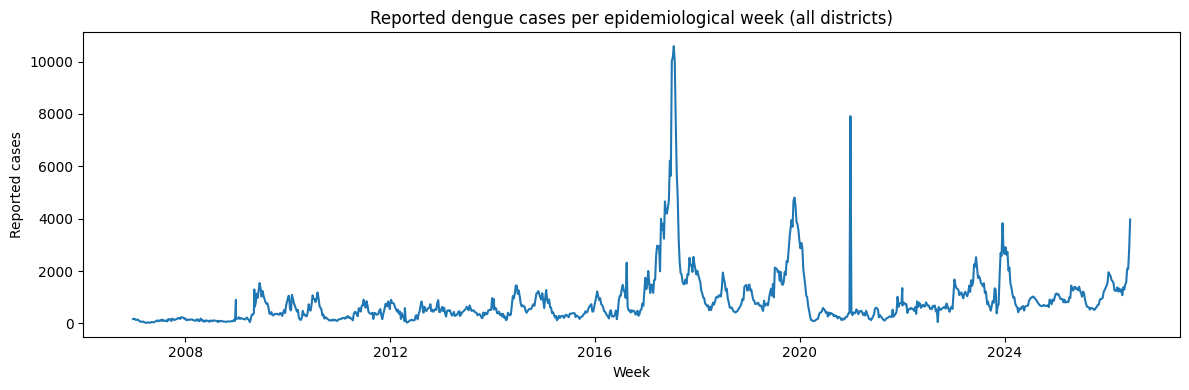

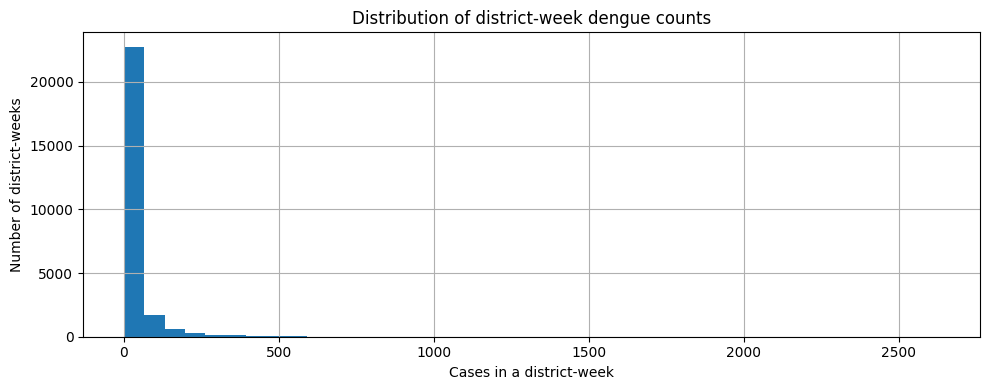

In [5]:
# Group the dengue data by epidemiological week and calculate the total number of reported cases across all districts for each week.

weekly_national = (
    dengue.groupby("Week_Start_Date", as_index=False)["Number_of_Cases"]
    .sum()  # Add the cases from all districts for each week.
    .sort_values("Week_Start_Date") # Arrange the weeks in chronological order.
)


# Create a new figure for the line chart with a width of 12 inches and a height of 4 inches.
plt.figure(figsize=(12, 4))

# Plot the weekly national dengue case totals over time. The dates are shown on the x-axis and the total cases on the y-axis.
plt.plot(weekly_national["Week_Start_Date"], weekly_national["Number_of_Cases"])

# Add a title to describe what the line chart represents.
plt.title("Reported dengue cases per epidemiological week (all districts)")

# Label the horizontal axis to show that it represents the weeks.
plt.xlabel("Week")

# Label the vertical axis to show the number of reported dengue cases.
plt.ylabel("Reported cases")
plt.tight_layout()

# Display the completed line chart.
plt.show()



# Create a new figure for the histogram with a width of 10 inches and a height of 4 inches.
plt.figure(figsize=(10, 4))

# Create a histogram showing how the district-week dengue case counts are distributed.
dengue["Number_of_Cases"].hist(bins=40)

# Add a title explaining what the histogram displays.
plt.title("Distribution of district-week dengue counts")

# Label the horizontal axis with the number of cases recorded in a single district during one epidemiological week.
plt.xlabel("Cases in a district-week")

# Label the vertical axis with the number of district-week records that fall into each histogram interval.
plt.ylabel("Number of district-weeks")
plt.tight_layout()

# Display the completed histogram.
plt.show()

# Add weekly weather features from Open-Meteo

Open-Meteo provides historical weather summaries including mean temperature, mean relative humidity, and precipitation. We request daily data for representative coordinates in each district, then aggregate it to weekly summaries.

In [6]:
# Approximate district-centre coordinates (latitude, longitude).
# They do not represent the weather conditions of every location in a district.
DISTRICT_COORDS = {
    "Colombo": (6.9271, 79.8612),
    "Gampaha": (7.0873, 80.0144),
    "Kalutara": (6.5854, 79.9607),
    "Kandy": (7.2906, 80.6337),
    "Matale": (7.4675, 80.6234),
    "Nuwara Eliya": (6.9497, 80.7891),
    "Galle": (6.0535, 80.2210),
    "Matara": (5.9549, 80.5550),
    "Hambantota": (6.1429, 81.1212),
    "Jaffna": (9.6615, 80.0255),
    "Kilinochchi": (9.3803, 80.3770),
    "Mannar": (8.9810, 79.9044),
    "Vavuniya": (8.7514, 80.4971),
    "Mullaitivu": (9.2671, 80.8142),
    "Batticaloa": (7.7310, 81.6747),
    "Ampara": (7.2975, 81.6820),
    "Trincomalee": (8.5874, 81.2152),
    "Kurunegala": (7.4863, 80.3623),
    "Puttalam": (8.0362, 79.8283),
    "Anuradhapura": (8.3114, 80.4037),
    "Polonnaruwa": (7.9403, 81.0188),
    "Badulla": (6.9934, 81.0550),
    "Monaragala": (6.8728, 81.3507),
    "Ratnapura": (6.7056, 80.3847),
    "Kegalle": (7.2513, 80.3464),
}

# Use a fixed end date
WEATHER_START = "2015-01-01"
WEATHER_END = "2025-12-31"

# Define a function to download historical daily weather data for a district using its coordinates and the requested date range.
def fetch_district_weather(district, lat, lon, start_date, end_date):
    url = "https://archive-api.open-meteo.com/v1/archive"

    # Specify the location, date range, weather variables, and time zone required for the API request.

    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start_date,
        "end_date": end_date,
        "daily": (
            "temperature_2m_mean,relative_humidity_2m_mean,"
            "precipitation_sum"
        ),
        "timezone": "Asia/Colombo"
    }

    # Send a GET request to the weather API.
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

     # Convert the API response from JSON format into a Python dictionary.
    payload = response.json()

    # Convert the date column from text into pandas datetime values.
    daily = pd.DataFrame(payload["daily"])
    daily["time"] = pd.to_datetime(daily["time"])
    daily["District"] = district

    # Rename the API column names to clearer names
    # then return the prepared daily weather DataFrame.
    return daily.rename(columns={
        "time": "Weather_Date",
        "temperature_2m_mean": "Mean_Temperature",
        "relative_humidity_2m_mean": "Mean_Relative_Humidity",
        "precipitation_sum": "Precipitation_mm"
    })

# Fetch weather only for districts present in the case dataset and with coordinates.
districts_to_fetch = sorted(set(dengue["District"]) & set(DISTRICT_COORDS))

# Create an empty list to store the weather DataFrame
weather_frames = []

for i, district in enumerate(districts_to_fetch, start=1):
    lat, lon = DISTRICT_COORDS[district]

    # Try to download the weather data for the current district.
    try:
        weather_frames.append(
            fetch_district_weather(
                district, lat, lon, WEATHER_START, WEATHER_END
            )
        )
        print(f"{i}/{len(districts_to_fetch)} weather downloaded: {district}")

    # Handle errors
    except Exception as exc:
        print(f"Weather download failed for {district}: {exc}")

if not weather_frames:
    raise RuntimeError(
        "No weather data was downloaded. Check your internet connection/API access."
    )

# Combine the weather DataFrames for all successfully downloaded districts into one DataFrame
weather_daily = pd.concat(weather_frames, ignore_index=True)

# Display the first five rows to inspect the downloaded weather data
display(weather_daily.head())

1/25 weather downloaded: Ampara
2/25 weather downloaded: Anuradhapura
3/25 weather downloaded: Badulla
4/25 weather downloaded: Batticaloa
5/25 weather downloaded: Colombo
6/25 weather downloaded: Galle
7/25 weather downloaded: Gampaha
Weather download failed for Hambantota: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=6.1429&longitude=81.1212&start_date=2015-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Crelative_humidity_2m_mean%2Cprecipitation_sum&timezone=Asia%2FColombo
Weather download failed for Jaffna: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=9.6615&longitude=80.0255&start_date=2015-01-01&end_date=2025-12-31&daily=temperature_2m_mean%2Crelative_humidity_2m_mean%2Cprecipitation_sum&timezone=Asia%2FColombo
Weather download failed for Kalutara: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=6.5854&longitude=79.

,Weather_Date,Mean_Temperature,Mean_Relative_Humidity,Precipitation_mm,District
0,2015-01-01,25.9,85,1.6,Ampara
1,2015-01-02,25.7,86,1.3,Ampara
2,2015-01-03,26.0,85,0.0,Ampara
3,2015-01-04,25.8,84,0.2,Ampara
4,2015-01-05,25.2,87,3.3,Ampara


# Aggregate daily weather to epidemiological weeks

In [7]:
# Match each daily weather record to the latest epidemiological week start
# for that district. This avoids repeatedly scanning the full weather table.


# Create an empty list to store the weekly weather DataFrame
weather_weekly_parts = []

# Select the district and epidemiological week columns from the dengue dataset.
# drop_duplicates() keeps only unique district-week combinations.
# sort_values() arranges the records by district and week.
case_weeks = (
    dengue[["District", "Week_Start_Date"]]
    .drop_duplicates()
    .sort_values(["District", "Week_Start_Date"])
)

# Process the weather data separately for each district.
for district in districts_to_fetch:

    # Select the current district's daily weather records,
    # sort them by date, and create a copy to work with.
    district_weather = (
        weather_daily[weather_daily["District"] == district]
        .sort_values("Weather_Date")
        .copy()
    )

    # Select the epidemiological weeks available for this district
    # and arrange them chronologically.
    district_weeks = (
        case_weeks[case_weeks["District"] == district]
        .sort_values("Week_Start_Date")
        .copy()
    )

    # Skip this district if it has no weather records or no case weeks.
    if district_weather.empty or district_weeks.empty:
        continue

    # Match each weather date with the most recent epidemiological
    # week start date that is on or before that weather date.
    # Both date columns must be sorted for merge_asof().
    assigned = pd.merge_asof(
        district_weather,
        district_weeks,
        left_on="Weather_Date",       # Date from the daily weather data.
        right_on="Week_Start_Date",   # Date of the epidemiological week.
        direction="backward",         # Match to the latest earlier date.
        allow_exact_matches=True      # Allow dates that are exactly equal.
    )

    # Remove weather records that could not be matched to a week start date.
    assigned = assigned.dropna(subset=["Week_Start_Date"])

    # Calculate how many days each weather record is after its week starts.
    assigned["Days_From_Week_Start"] = (
        assigned["Weather_Date"] - assigned["Week_Start_Date"]
    ).dt.days

    # Keep only weather records from day 0 to day 6 of each week.
    # This ensures that each record belongs to the corresponding
    # seven-day epidemiological week.
    assigned = assigned[
        assigned["Days_From_Week_Start"].between(0, 6)
    ]

    # Explicitly set the district name to ensure that this column
    # contains the correct district for every matched record.
    assigned["District"] = district

    # Group the daily weather records by district and epidemiological week.
    # Calculate weekly summaries from the daily weather measurements.
    weekly = assigned.groupby(
        ["District", "Week_Start_Date"], as_index=False
    ).agg(
        # Calculate the average daily mean temperature for the week.
        Mean_Temperature=("Mean_Temperature", "mean"),

        # Calculate the average daily relative humidity for the week.
        Mean_Relative_Humidity=("Mean_Relative_Humidity", "mean"),

        # Add daily precipitation values to obtain weekly precipitation.
        Precipitation_mm=("Precipitation_mm", "sum"),

        # Count the number of unique dates with weather records.
        # This helps identify weeks with incomplete weather coverage.
        Weather_Days=("Weather_Date", "nunique")
    )

    # Save this district's weekly weather summary for later combination.
    weather_weekly_parts.append(weekly)


# Combine the weekly weather summaries from all districts into one DataFrame.
# ignore_index=True creates a new continuous row index.
weather_weekly = pd.concat(weather_weekly_parts, ignore_index=True)

# Print the total number of district-week weather records.
print("Weekly weather rows:", len(weather_weekly))

# Display the first five rows if the weekly weather DataFrame is not empty.
if not weather_weekly.empty:
    display(weather_weekly.head())


# Merge the dengue case data with the weekly weather summaries.
data = dengue.merge(
    # Remove Weather_Days because it is only used as a coverage check.
    # If no weekly weather data exists, use the empty DataFrame instead.
    weather_weekly.drop(columns=["Weather_Days"])
    if not weather_weekly.empty else weather_weekly,

    # Match records using both district name and epidemiological week.
    on=["District", "Week_Start_Date"],

    # Keep all dengue records, even when matching weather data is missing.
    how="left",

    # Require each district-week key to occur at most once in each DataFrame.
    # This helps detect unexpected duplicate keys during the merge.
    validate="one_to_one"
)

# Display the number of rows and columns in the merged dataset.
print("Merged shape:", data.shape)

# Calculate the proportion of missing values in each weather feature.
# For example, 0.10 means 10% of the rows have missing values in that column.
print("Weather missingness:")
display(
    data[
        [
            "Mean_Temperature",
            "Mean_Relative_Humidity",
            "Precipitation_mm"
        ]
    ].isna().mean()
)

Weekly weather rows: 7840


,District,Week_Start_Date,Mean_Temperature,Mean_Relative_Humidity,Precipitation_mm,Weather_Days
0,Ampara,2015-01-03,25.214286,83.285714,6.7,7
1,Ampara,2015-01-10,24.742857,75.000000,1.8,7
2,Ampara,2015-01-17,25.085714,81.000000,5.1,7
3,Ampara,2015-01-24,25.200000,82.285714,22.1,7
4,Ampara,2015-01-31,24.828571,85.571429,36.9,7


Merged shape: (25818, 10)
Weather missingness:


,0
Mean_Temperature,0.696336
Mean_Relative_Humidity,0.696336
Precipitation_mm,0.696336


# Create history features and next-week target

In [8]:
# Sort the dataset by District and Week Start Date
data = data.sort_values(["District", "Week_Start_Date"]).reset_index(drop=True)

# Store the dengue cases for the current week.
data["Cases_This_Week"] = data["Number_of_Cases"]

# Create lag features for the previous 1, 2, 3, and 4 weeks.
for lag in [1, 2, 3, 4]:
    # Get the dengue cases from 'lag' weeks earlier
    shifted_cases = data.groupby("District")["Number_of_Cases"].shift(lag)
    # Get the corresponding date from the lagged record.
    shifted_dates = data.groupby("District")["Week_Start_Date"].shift(lag)
    # Calculate the date that should correspond to the lagged week.
    expected_date = data["Week_Start_Date"] - pd.to_timedelta(7 * lag, unit="D")
    # Keep the lagged cases only when the expected previous week exists
    data[f"Cases_Lag_{lag}"] = shifted_cases.where(shifted_dates == expected_date)

# Obtain the dengue case count for the following week.
next_cases = data.groupby("District")["Number_of_Cases"].shift(-1)
# Obtain the date corresponding to the next week's record.
next_dates = data.groupby("District")["Week_Start_Date"].shift(-1)
# Calculate the expected date of the following week.
expected_next_date = data["Week_Start_Date"] + pd.Timedelta(days=7)
# Create the prediction target.
data["Next_Week_Cases"] = next_cases.where(next_dates == expected_next_date)

# Count the number of rows for which a valid next-week
print("Rows with next-week target:", data["Next_Week_Cases"].notna().sum())
# Display the dataset excluding the last 10 rows
display(data.head(-10))

Rows with next-week target: 23632


,District,Number_of_Cases,Week_Start_Date,Month,Year,Week,Week_End_Date,Mean_Temperature,Mean_Relative_Humidity,Precipitation_mm,Cases_This_Week,Cases_Lag_1,Cases_Lag_2,Cases_Lag_3,Cases_Lag_4,Next_Week_Cases
0,Ampara,0,2006-12-23,12,2006,52,12/29/2006,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0.0
1,Ampara,0,2006-12-30,12,2007,1,1/5/2007,NaN,NaN,NaN,0,0.0,NaN,NaN,NaN,0.0
2,Ampara,0,2007-01-06,1,2007,2,1/12/2007,NaN,NaN,NaN,0,0.0,0.0,NaN,NaN,0.0
3,Ampara,0,2007-01-13,1,2007,3,1/19/2007,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,0.0
4,Ampara,0,2007-01-20,1,2007,4,1/26/2007,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25803,Vavuniya,0,2026-03-07,3,2026,11,3/13/2026,NaN,NaN,NaN,0,5.0,5.0,5.0,4.0,4.0
25804,Vavuniya,4,2026-03-14,3,2026,12,3/20/2026,NaN,NaN,NaN,4,0.0,5.0,5.0,5.0,1.0
25805,Vavuniya,1,2026-03-21,3,2026,13,3/27/2026,NaN,NaN,NaN,1,4.0,0.0,5.0,5.0,5.0
25806,Vavuniya,5,2026-03-28,3,2026,14,4/3/2026,NaN,NaN,NaN,5,1.0,4.0,0.0,5.0,39.0


# Chronological train/test split and target threshold

In [9]:
# Set the cutoff date for training and testing
CUTOFF_DATE = pd.Timestamp("2024-01-01")

# Get case values from the training period
train_case_values = data.loc[
    data["Week_Start_Date"] < CUTOFF_DATE, "Number_of_Cases"]

# Calculate and view the 75th percentile as the risk threshold
risk_threshold = train_case_values.quantile(0.75)
print("Training-period 75th percentile threshold:", risk_threshold)

# Create the elevated dengue risk target
data["Elevated_Next_Week"] = np.where(
    data["Next_Week_Cases"].notna(),
    (data["Next_Week_Cases"] > risk_threshold).astype(int),
    np.nan
)

# Select the features for the model
feature_columns = [
    "District",
    "Week_Start_Date",
    "Cases_This_Week",
    "Cases_Lag_1", "Cases_Lag_2", "Cases_Lag_3", "Cases_Lag_4",
    "Mean_Temperature", "Mean_Relative_Humidity", "Precipitation_mm"
]

# Remove rows with missing values
model_data = data.dropna(
    subset=feature_columns + ["Elevated_Next_Week"]
).copy()

# Convert the target to integer type
model_data["Elevated_Next_Week"] = model_data["Elevated_Next_Week"].astype(int)

# Split data into training and testing sets
train = model_data[model_data["Week_Start_Date"] < CUTOFF_DATE].copy()
test = model_data[model_data["Week_Start_Date"] >= CUTOFF_DATE].copy()

# Prepare training features and target
X_train = train[feature_columns].drop(columns=["Week_Start_Date"])
y_train = train["Elevated_Next_Week"]
# Prepare testing features and target
X_test = test[feature_columns].drop(columns=["Week_Start_Date"])
y_test = test["Elevated_Next_Week"]

# Display dataset sizes and class proportions
print("Training rows:", len(train), "| Test rows:", len(test))
print("Training class proportions:\n", y_train.value_counts(normalize=True))
print("Test class proportions:\n", y_test.value_counts(normalize=True))

# Check that both training and testing sets contain data
if len(train) == 0 or len(test) == 0:
    raise ValueError(
        "Train/test set is empty. Check dataset date coverage and weather merge.")

Training-period 75th percentile threshold: 28.0
Training rows: 5306 | Test rows: 1190
Training class proportions:
 Elevated_Next_Week
0    0.6634
1    0.3366
Name: proportion, dtype: float64
Test class proportions:
 Elevated_Next_Week
0    0.636975
1    0.363025
Name: proportion, dtype: float64


# Build preprocessing and model pipelines

In [10]:

# Identify the categorical feature that contains text-based categories.
# District names will be converted into numerical columns using one-hot encoding.
categorical_features = ["District"]

# Identify all remaining columns in X_train as numerical features.
# These may include weather measurements and historical dengue case counts.
numeric_features = [c for c in X_train.columns if c != "District"]


# Create the numerical preprocessing pipeline for Logistic Regression.
numeric_preprocess_scaled = Pipeline(steps=[

    # Replace missing numerical values with the median of each feature.
    # The median is less sensitive to extreme values than the mean.
    ("imputer", SimpleImputer(strategy="median")),

    # Standardize numerical features so they have a mean of 0 and a standard deviation of 1.
    # Scaling is useful for Logistic Regression because features may have very different numerical ranges.
    ("scaler", StandardScaler())

])


# Create the preprocessing pipeline for categorical features.
categorical_preprocess = Pipeline(steps=[

    # Replace missing categorical values with the most frequent value
    # in the corresponding feature.
    ("imputer", SimpleImputer(strategy="most_frequent")),

    # Convert each district category into binary indicator columns.
    ("onehot", OneHotEncoder(handle_unknown="ignore"))

])


# Combine numerical and categorical preprocessing for Logistic Regression.
preprocessor_logistic = ColumnTransformer(transformers=[

    # Impute missing numerical values and scale numerical features.
    # Apply these steps only to the columns listed in numeric_features.
    ("numeric", numeric_preprocess_scaled, numeric_features),

    # Impute missing district values and apply one-hot encoding.
    # Apply these steps only to the categorical feature.
    ("categorical", categorical_preprocess, categorical_features)

])


# Create a separate preprocessing setup for Random Forest.
preprocessor_forest = ColumnTransformer(transformers=[

    # Fill missing numerical values with the median.
    # Scaling is not included because Random Forest generally does not require numerical features to be standardized.
    ("numeric", SimpleImputer(strategy="median"), numeric_features),

    # Apply the same missing-value handling and one-hot encoding
    # to the District feature.
    ("categorical", categorical_preprocess, categorical_features)

])


# Build the complete Logistic Regression pipeline.
# Preprocessing is performed before the classifier makes predictions.
logistic_model = Pipeline(steps=[

    # Prepare the numerical and categorical input features.
    ("preprocess", preprocessor_logistic),

    # Create the Logistic Regression classifier.
    ("classifier", LogisticRegression(

        # Allow up to 2,000 iterations to help the model converge.
        max_iter=2000,

        # Give greater importance to the minority class when calculating
        # class weights, which can help with imbalanced target classes.
        class_weight="balanced",

        # Set a fixed random seed for reproducible results where applicable.
        random_state=RANDOM_STATE
    ))

])


# Build the complete Random Forest pipeline.
forest_model = Pipeline(steps=[

    # Prepare the input features using the Random Forest preprocessor.
    ("preprocess", preprocessor_forest),

    # Create the Random Forest classification model.
    ("classifier", RandomForestClassifier(

        # Build an ensemble containing 300 decision trees.
        n_estimators=300,

        # Allow trees to grow without a fixed maximum depth.
        max_depth=None,

        # Require at least two training samples in a leaf node.
        # This can help reduce overly complex trees.
        min_samples_leaf=2,

        # Adjust class weights to help address class imbalance.
        class_weight="balanced",

        # Set a fixed random seed for reproducible results.
        random_state=RANDOM_STATE,

        # Use all available CPU cores for parallel processing.
        n_jobs=-1
    ))

])

# Train both models

In [11]:
# used created models to train using model.fit
logistic_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

print("Both models trained.")

Both models trained.


# Evaluate with suitable metrics

In [12]:

# Define a function to evaluate a trained classification model using the test dataset.
def evaluate_model(name, model, X_test, y_test):

    # Use the trained model to predict the target class for each test record.
    pred = model.predict(X_test)

    # Get the probability of belonging to class 1 (the positive class). If the model does not support probability predictions, use None.
    scores = (
        model.predict_proba(X_test)[:, 1]
        if hasattr(model, "predict_proba")
        else None
    )

    # Calculate the evaluation metrics and store them in a dictionary.
    result = {

        # Store the model's name for identification in the results table.
        "Model": name,

        # Accuracy: proportion of all predictions that are correct.
        "Accuracy": accuracy_score(y_test, pred),

        # Balanced accuracy: average recall across the classes.
        # This is useful when the target classes are imbalanced.
        "Balanced_Accuracy": balanced_accuracy_score(y_test, pred),

        # Precision: proportion of positive predictions that are correct.
        "Precision": precision_score(y_test, pred, zero_division=0),

        # Recall: proportion of actual positive cases correctly identified.
        "Recall": recall_score(y_test, pred, zero_division=0),

        # F1-score: combines precision and recall into a single metric.
        # It is their harmonic mean.
        "F1": f1_score(y_test, pred, zero_division=0),

        # ROC-AUC measures how well the model distinguishes between the two classes using predicted probabilities.
        "ROC_AUC": (
            roc_auc_score(y_test, scores)
            if scores is not None and y_test.nunique() == 2
            else np.nan
        )
    }

    # Return both the evaluation metrics and the individual predictions.
    return result, pred


# Evaluate the Logistic Regression model using the test dataset.
# Store its metrics in log_result and its predictions in log_pred.
log_result, log_pred = evaluate_model(
    "Logistic Regression", logistic_model, X_test, y_test
)

# Evaluate the Random Forest model using the same test dataset.
# Store its metrics in rf_result and its predictions in rf_pred.
rf_result, rf_pred = evaluate_model(
    "Random Forest", forest_model, X_test, y_test
)


# Combine both models' evaluation results into a single pandas DataFrame.
# set_index("Model") makes the model name the row label.
results = pd.DataFrame([log_result, rf_result]).set_index("Model")

# Round the displayed metric values to three decimal places to display
display(results.round(3))

,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,,
Logistic Regression,0.928,0.927,0.883,0.924,0.903,0.977
Random Forest,0.924,0.922,0.880,0.914,0.897,0.979


# Confusion matrices and classification reports


 Logistic Regression
              precision    recall  f1-score   support

Not elevated       0.96      0.93      0.94       758
    Elevated       0.88      0.92      0.90       432

    accuracy                           0.93      1190
   macro avg       0.92      0.93      0.92      1190
weighted avg       0.93      0.93      0.93      1190



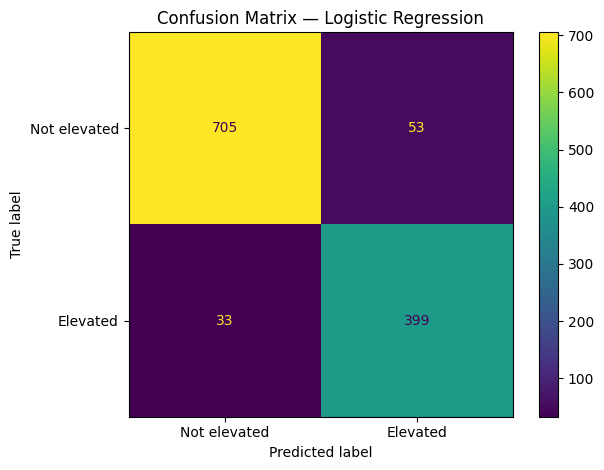


 Random Forest
              precision    recall  f1-score   support

Not elevated       0.95      0.93      0.94       758
    Elevated       0.88      0.91      0.90       432

    accuracy                           0.92      1190
   macro avg       0.91      0.92      0.92      1190
weighted avg       0.92      0.92      0.92      1190



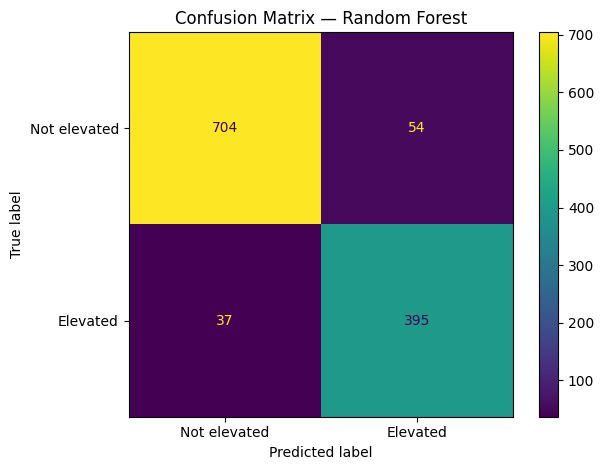

In [13]:

# Evaluate and visualize the results of both trained classification models.
# Each tuple contains the model name, trained model, and its predictions.
for name, model, pred in [
    ("Logistic Regression", logistic_model, log_pred),
    ("Random Forest", forest_model, rf_pred)
]:

    # Print the current model's name so its results are easy to identify.
    print("\n", name)

    # Generate a classification report comparing the actual test labels with the model's predicted labels.
    # The report includes precision, recall, F1-score, and support.
    # target_names assigns readable labels to classes 0 and 1.
    print(classification_report(
        y_test,
        pred,
        target_names=["Not elevated", "Elevated"],
        zero_division=0
    ))

    # Calculate the confusion matrix using the actual and predicted labels.
    # labels=[0, 1] ensures the classes appear in the expected order: 0 = Not elevated, 1 = Elevated.
    cm = confusion_matrix(y_test, pred, labels=[0, 1])

    # Create a display object to visualize the confusion matrix.
    # Use descriptive class names instead of numerical labels.
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not elevated", "Elevated"]
    )

    # Draw the confusion matrix as a plot.
    disp.plot()

    # Add a title containing the current model's name.
    plt.title(f"Confusion Matrix — {name}")

    # Adjust spacing so the title and labels fit within the figure.
    plt.tight_layout()

    # Display the confusion matrix.
    plt.show()

# Compare models visually

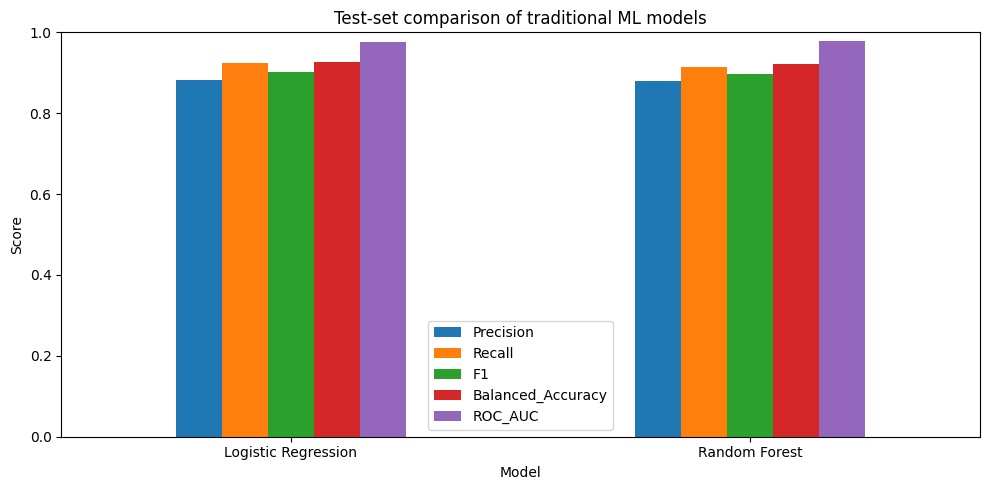

In [14]:
metrics_to_plot = ["Precision", "Recall", "F1", "Balanced_Accuracy", "ROC_AUC"]
results[metrics_to_plot].plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
plt.title("Test-set comparison of traditional ML models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Interpretation and limitations

In [15]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Logistic_Predicted": log_pred,
    "RandomForest_Predicted": rf_pred
}, index=test.index)

print("False negatives (Logistic Regression):",
      int(((comparison["Actual"] == 1) & (comparison["Logistic_Predicted"] == 0)).sum()))
print("False negatives (Random Forest):",
      int(((comparison["Actual"] == 1) & (comparison["RandomForest_Predicted"] == 0)).sum()))

print("Test dates:", test["Week_Start_Date"].min(), "to", test["Week_Start_Date"].max())

False negatives (Logistic Regression): 33
False negatives (Random Forest): 37
Test dates: 2024-01-06 00:00:00 to 2025-12-06 00:00:00
